# Cut-site prediction: ESM3Di vs base ESM++ embeddings

**Question.** Does fine-tuning ESM++ on viral structures (ESM3Di) produce per-residue
representations that are better for a viral task it was *not* trained on?

Cleavage-site prediction in *Amarillovirales* polyproteins is the test task. The only
comparison that matters here is **ESM3Di embeddings vs non-fine-tuned ESM++ embeddings**,
with everything else held identical: same sequences, same labels, same splits, same
classifier heads, same hyperparameters, same seeds.

This is a representation-quality claim, not a cleavage-prediction tool claim. Dedicated
cut-site predictors exist (3CLP, `clear-bio/ingmar`) and are out of scope.

### What differs from `cut_flavi.ipynb`
| | original | here |
|---|---|---|
| Baseline | none (FFN vs Transformer only) | **non-fine-tuned ESM++**, identical pipeline |
| Held-out clades | Orthoflavivirus only | **all four**, leave-one-group-out |
| Split | random over flattened residue positions (leaks: residues of one polyprotein in both train and val) | whole sequences only, by genus |
| Hyperparameters | swept, ranked by held-out AP, reported on the same group | **fixed a priori** (paper Methods), identical for both arms |
| Unannotated sequences | 136/231 included as all-negative | **excluded** (no annotation ≠ no cleavage) |
| Scoring | AP at exact single-residue resolution | + tolerance windows (±2, ±5) and top-k site recovery |
| Controls | none | linear probe, mlp64, shuffled labels |

### Checkpoint note
The original notebook loads `checkpoints/esm3di_from_mlm/epoch_5.pt`, which does not exist
on this machine. This loads the published PEFT adapter from the Hugging Face repo
`cactuskid13/ESM3di_Small_MLM_3di` (subfolder `hf_compatible`), resolved cache-first exactly
as `src/esm3di/inference/predictor.py` does. Its config matches the paper Methods
(r=16, α=32, dropout 0.01) on the same base model and revision. It is byte-identical to the
copy previously used from `/users/fweikert/checkpoints/hf_compatible`
(`adapter_model.safetensors` sha256 `461593e78b289310…`), so results are unchanged by the
switch. It cannot be verified byte-for-byte against the absent `.pt`.

In [1]:
from pathlib import Path
import re, sys, time, hashlib, json
import numpy as np, pandas as pd, torch, torch.nn as nn
import matplotlib.pyplot as plt

BASE      = Path("/users/fweikert/ESM3di/experiments/analyses/polyprotein_cut/dataset/Amarillovirales")
HF_MODEL  = "Synthyra/ESMplusplus_small"
HF_REV    = "46c5f7d562e47d4c14165b424c71ab7db008e6fb"
ESM3DI_REPO = "cactuskid13/ESM3di_Small_MLM_3di"   # src/esm3di/inference/predictor.py DEFAULT_HF_REPO

def resolve_adapter(repo_id=ESM3DI_REPO, revision=None):
    """Resolve the ESM3Di PEFT adapter from the Hub, cache-first then download.
    Mirrors ESM3DiPredictor in src/esm3di/inference/predictor.py."""
    from huggingface_hub import snapshot_download
    pats = ["hf_compatible", "hf_compatible/**"]
    try:
        root = snapshot_download(repo_id=repo_id, revision=revision,
                                 allow_patterns=pats, local_files_only=True)
    except Exception:
        root = snapshot_download(repo_id=repo_id, revision=revision,
                                 allow_patterns=pats, local_files_only=False)
    return Path(root) / "hf_compatible"

ADAPTER = resolve_adapter()
CACHE     = Path("/scratch/fweikert/cutsite_emb"); CACHE.mkdir(parents=True, exist_ok=True)
DEV       = "cuda" if torch.cuda.is_available() else "cpu"

# classifier hyperparameters - fixed a priori from the paper Methods, never tuned here
HID, INT, P_HID, P_IN = 256, 128, 0.45, 0.10
LR, WD, EPOCHS, BS    = 1e-3, 3e-4, 12, 4096
SEEDS = [0, 1, 2, 3, 4]
seqkey = lambda s: hashlib.sha1(s.encode()).hexdigest()[:16]
# plotting palette / labels (used from section 7 onwards)
AL = {"base": "ESM++ (base)", "esm3di": "ESM3Di"}
C  = {"base": "#8c8c8c", "esm3di": "#2f6fb5"}
SH = {"Hepacivirus-CHH": "Hepaci", "Orthoflavivirus-CHH": "Orthoflavi",
      "Pegivirus-CHH": "Pegi", "Pestivirus-CHH": "Pesti"}
ML = {"roc_auc": "ROC AUC", "ap": "AP", "ap_t2": "AP ±2", "ap_t5": "AP ±5", "topk": "top-k"}

print("device:", DEV)
print("adapter:", ADAPTER)

device: cpu
adapter: /users/fweikert/.cache/huggingface/hub/models--cactuskid13--ESM3di_Small_MLM_3di/snapshots/b32e8d308efd435be015122d7a1ca8f2dc671e86/hf_compatible


## 1. Data: alignments and ICTV cleavage labels
Same parsing as `cut_flavi.ipynb` (cells 1–4, 8).

In [2]:
def parse_clustal_fallback(path):
    seq_by_id, order = {}, []
    for raw in path.open("r", encoding="utf-8", errors="ignore"):
        line = raw.rstrip("\n"); st = line.strip()
        if not st or st.upper().startswith("CLUSTAL"): continue
        if all(ch in "*:. -" for ch in st): continue
        m = re.match(r"^(?P<ident>.+?)\s+([A-Za-z\-\.]+)(?:\s+\d+)?\s*$", line)
        if not m: continue
        ident = m.group("ident").strip()
        chunk = re.search(r"([A-Za-z\-\.]+)(?:\s+\d+)?\s*$", line).group(1)
        if ident not in seq_by_id: seq_by_id[ident] = []; order.append(ident)
        seq_by_id[ident].append(chunk)
    return [{"identifier": i, "alignment_sequence": "".join(seq_by_id[i])} for i in order]

def parse_ictv(path):
    """FT SITE ranges whose note is 'Cleavage'; keep the first residue of each range."""
    by_id, cur, pend, is_clv = {}, None, None, False
    def commit(sid):
        nonlocal pend, is_clv
        if sid is not None and pend is not None and is_clv:
            by_id[sid]["pos"].append(pend[0])
        pend, is_clv = None, False
    for raw in path.open("r", encoding="utf-8", errors="ignore"):
        line = raw.rstrip("\n")
        if line.startswith("ID"):
            commit(cur); m = re.match(r"^ID\s+(\S+)", line); cur = m.group(1) if m else None
            if cur and cur not in by_id: by_id[cur] = {"pos": []}
            continue
        if line.startswith("//"): commit(cur); cur = None; continue
        if cur is None: continue
        m = re.match(r"^FT\s+SITE\s+(\d+)\.\.(\d+)", line)
        if m: commit(cur); pend = (int(m.group(1)), int(m.group(2))); is_clv = False; continue
        if pend is not None and '/note="Cleavage"' in line: is_clv = True; continue
        if pend is not None and line.startswith("FT") and not line.startswith("FT" + " "*19):
            commit(cur); continue
    commit(cur)
    return {k: sorted(set(v["pos"])) for k, v in by_id.items() if v["pos"]}

def build_dataset():
    rows = []
    for folder in sorted(p for p in BASE.iterdir() if p.is_dir()):
        for aln in sorted(folder.glob("*.aln")):
            for r in parse_clustal_fallback(aln):
                r["group"] = folder.name; rows.append(r)
    df = pd.DataFrame(rows)
    df["original_sequence"] = (df["alignment_sequence"].str.replace("-", "", regex=False)
                                                       .str.replace(".", "", regex=False))
    df["n_AA"] = df["original_sequence"].str.len()
    labels = {}
    for p in sorted(BASE.glob("*/hpraise*_ICTV")):
        for sid, pos in parse_ictv(p).items(): labels.setdefault(sid, []).extend(pos)
    labels = {k: sorted(set(v)) for k, v in labels.items()}
    df["cut_positions"] = [labels.get(str(i), []) for i in df["identifier"]]
    df["n_sites"] = df["cut_positions"].apply(len)
    masks = []
    for n, pos in zip(df["n_AA"], df["cut_positions"]):
        m = np.zeros(int(n), dtype=np.float32)
        for p in pos:
            if 0 <= int(p)-1 < n: m[int(p)-1] = 1.0
        masks.append(m)
    df["mask"] = masks
    df["key"]  = df["original_sequence"].map(seqkey)
    return df

full = build_dataset()
print(f"all alignment sequences : {len(full)}  (unique ids {full.identifier.nunique()})")
print(f"labelled                : {(full.n_sites>0).sum()}/{len(full)}")
print(f"all positions / positives: {int(full.n_AA.sum())} / {int(full.n_sites.sum())}")

all alignment sequences : 231  (unique ids 164)
labelled                : 95/231
all positions / positives: 775319 / 940


### Verification against the original notebook

`cut_flavi.ipynb` recorded 231 alignment sequences, 775,319 residue positions, 940 positive
labels, 95/231 labelled, and an Orthoflavivirus test fold of 548,672 tokens with 621
positives. The assertions below fail loudly if parsing has drifted.

In [3]:
assert len(full) == 231,                    f"n sequences {len(full)}"
assert int(full.n_AA.sum()) == 775_319,     f"positions {int(full.n_AA.sum())}"
assert int(full.n_sites.sum()) == 940,      f"positives {int(full.n_sites.sum())}"
assert int((full.n_sites > 0).sum()) == 95, f"labelled {(full.n_sites>0).sum()}"
o = full[full.group == "Orthoflavivirus-CHH"]
assert int(o.n_AA.sum()) == 548_672 and int(o.n_sites.sum()) == 621
print("reproduces cut_flavi.ipynb exactly")

# duplicate identifiers never span groups, so leave-one-group-out cannot leak through them
d = full.groupby("identifier").group.nunique()
assert (d == 1).all(); print(f"{(full.identifier.duplicated()).sum()} duplicate rows, none crossing groups")

reproduces cut_flavi.ipynb exactly
67 duplicate rows, none crossing groups


### Restrict to annotated sequences

136 of 231 sequences carry no ICTV annotation. The original notebook gave them all-zero
masks, i.e. treated "unannotated" as "no cleavage sites". That injects false negatives and
depresses the positive rate from 0.295% to 0.121%. They are dropped here.

In [4]:
lab = full[full.n_sites > 0].reset_index(drop=True)
summary = (lab.groupby("group")
              .agg(sequences=("identifier","size"), unique=("identifier","nunique"),
                   positions=("n_AA","sum"), positives=("n_sites","sum")))
summary["positive_rate_%"] = (100*summary.positives/summary.positions).round(3)
print(summary.to_string())
print(f"\nTOTAL {len(lab)} sequences, {int(lab.n_AA.sum())} positions, "
      f"{int(lab.n_sites.sum())} positives ({100*lab.n_sites.sum()/lab.n_AA.sum():.3f}%)")
print(f"sites per sequence: median {int(lab.n_sites.median())}, range {lab.n_sites.min()}-{lab.n_sites.max()}")

                     sequences  unique  positions  positives  positive_rate_%
group                                                                        
Hepacivirus-CHH              8       8      23655         79            0.334
Orthoflavivirus-CHH         55      30     187370        621            0.331
Pegivirus-CHH               19      19      57245        109            0.190
Pestivirus-CHH              13      13      50841        131            0.258

TOTAL 95 sequences, 319111 positions, 940 positives (0.295%)
sites per sequence: median 11, range 1-12


## 2. Metrics
`scikit-learn` is absent from this environment, so ROC AUC and average precision are implemented directly and unit-tested against hand-computable cases.

In [5]:
def roc_auc(y, s):
    y = np.asarray(y).astype(bool); s = np.asarray(s, dtype=np.float64)
    npos, nneg = int(y.sum()), int((~y).sum())
    if npos == 0 or nneg == 0: return float("nan")
    order = np.argsort(s, kind="mergesort"); sr = s[order]
    ranks = np.empty(len(s)); i = 0
    while i < len(sr):                                    # average ranks within ties
        j = i
        while j+1 < len(sr) and sr[j+1] == sr[i]: j += 1
        ranks[order[i:j+1]] = (i+j)/2.0 + 1.0; i = j+1
    return (ranks[y].sum() - npos*(npos+1)/2.0) / (npos*nneg)

def average_precision(y, s):
    """sklearn-equivalent: sum_n (R_n - R_{n-1}) * P_n over distinct thresholds."""
    y = np.asarray(y).astype(bool); s = np.asarray(s, dtype=np.float64)
    npos = int(y.sum())
    if npos == 0: return float("nan")
    order = np.argsort(-s, kind="mergesort"); ys, ss = y[order], s[order]
    tp, fp = np.cumsum(ys), np.cumsum(~ys)
    keep = np.r_[np.nonzero(np.diff(ss))[0], len(ss)-1]
    tp, fp = tp[keep], fp[keep]
    prec, rec = tp/np.maximum(tp+fp, 1e-12), tp/npos
    return float(np.sum(np.diff(np.r_[0.0, rec]) * prec))

def dilate(mask, w):
    """Positions within +/-w of a true site count as positive."""
    m = np.asarray(mask).astype(bool)
    if w <= 0: return m
    out = m.copy()
    for k in range(1, w+1):
        out[k:] |= m[:-k]; out[:-k] |= m[k:]
    return out

def topk_site_recovery(scores, true_pos, tol=2, nms=5):
    """Greedy peak-picking with non-max suppression, k = number of true sites.
    Each true site may be matched at most once. Returns (fraction, hits, n_true)."""
    scores = np.asarray(scores, dtype=np.float64); true_pos = np.asarray(sorted(true_pos), int)
    if len(true_pos) == 0: return float("nan"), 0, 0
    k = len(true_pos); avail = np.ones(len(scores), bool); picks = []
    for idx in np.argsort(-scores, kind="mergesort"):
        if len(picks) >= k: break
        if not avail[idx]: continue
        picks.append(idx); avail[max(0, idx-nms):idx+nms+1] = False
    unmatched, hits = set(true_pos.tolist()), 0
    for p in picks:
        cand = [t for t in unmatched if abs(t-p) <= tol]
        if cand: unmatched.discard(min(cand, key=lambda t: abs(t-p))); hits += 1
    return hits/len(true_pos), hits, len(true_pos)

In [6]:
# unit tests
assert roc_auc([0,0,1,1],[.1,.2,.8,.9]) == 1.0
assert roc_auc([0,0,1,1],[.9,.8,.2,.1]) == 0.0
assert roc_auc([0,1,0,1],[.5,.5,.5,.5]) == 0.5           # all ties
assert abs(roc_auc([1,0,1,0],[.9,.8,.7,.6]) - 0.75) < 1e-12
assert abs(average_precision([1,0,1,0],[.9,.8,.7,.6]) - (0.5 + 0.5*2/3)) < 1e-12
assert average_precision([0,0,1,1],[.1,.2,.8,.9]) == 1.0
_r = np.random.default_rng(0); _y = _r.random(200_000) < 0.01
assert abs(average_precision(_y, _r.random(200_000)) - 0.01) < 2e-3   # AP of noise ~ base rate
assert abs(roc_auc(_y, _r.random(200_000)) - 0.5) < 1e-2
_m = np.zeros(10, bool); _m[5] = True; assert dilate(_m,2).sum() == 5
_sc = np.zeros(100); _sc[11] = _sc[52] = _sc[90] = 1.0
assert topk_site_recovery(_sc, [10,50,90], tol=2)[0] == 1.0
assert abs(topk_site_recovery(_sc, [10,50,90], tol=1)[0] - 2/3) < 1e-12
print("all metric unit tests pass")

all metric unit tests pass


## 3. Embeddings
Two arms from the *same* base model and revision: with the ESM3Di LoRA adapter, and without it.

In [7]:
def build_model(with_lora):
    from transformers import AutoModel
    m = AutoModel.from_pretrained(HF_MODEL, revision=HF_REV, trust_remote_code=True)
    tok = m.tokenizer                       # AutoTokenizer cannot resolve EsmSequenceTokenizer
    if with_lora:
        from peft import PeftModel
        m = PeftModel.from_pretrained(m, ADAPTER)
    return m.eval().to(DEV), tok

def extract(tag, with_lora, seqs):
    path = CACHE / f"emb_{tag}.npz"
    if path.exists():
        z = np.load(path); return {k: z[k] for k in z.files}
    model, tok = build_model(with_lora); store = {}; t0 = time.time()
    for i, (k, s) in enumerate(seqs.items(), 1):
        enc = {kk: vv.to(DEV) for kk, vv in tok([s], return_tensors="pt").items()}
        with torch.no_grad(), torch.autocast(DEV, dtype=torch.bfloat16):
            h = model(**enc).last_hidden_state[0, 1:-1]      # strip <cls> / <eos>
        h = h.float().cpu().numpy().astype(np.float16)
        assert h.shape[0] == len(s)
        store[k] = h
        if i % 30 == 0 or i == len(seqs): print(f"  [{tag}] {i}/{len(seqs)} {time.time()-t0:.0f}s", flush=True)
    np.savez(path, **store); del model; torch.cuda.empty_cache()
    return store

seqs = {seqkey(s): s for s in lab["original_sequence"]}
print(f"{len(lab)} labelled rows -> {len(seqs)} unique sequences, "
      f"length {min(map(len,seqs.values()))}-{max(map(len,seqs.values()))}")
EMB = {"esm3di": extract("esm3di", True, seqs), "base": extract("base", False, seqs)}
print("embedding dim:", next(iter(EMB["base"].values())).shape[1])

95 labelled rows -> 90 unique sequences, length 2748-3989


embedding dim: 960


In [8]:
# the adapter must actually change the representation
_k = next(iter(seqs)); a, b = EMB["esm3di"][_k].astype(np.float32), EMB["base"][_k].astype(np.float32)
cos = (a*b).sum(1) / (np.linalg.norm(a,axis=1)*np.linalg.norm(b,axis=1))
print(f"per-residue cosine(ESM3Di, base): mean {cos.mean():.4f}  min {cos.min():.4f}")
assert cos.mean() < 0.99, "adapter had no effect"
print("adapter is active")

per-residue cosine(ESM3Di, base): mean 0.6395  min 0.0042
adapter is active


## 4. Leave-one-group-out

Train on three genera, test on the fourth. Features standardised with **training-fold**
statistics so the two arms cannot differ merely by scale. Three heads are used to show the
result is not an artefact of one architecture or of hyperparameters that were originally
tuned on ESM3Di embeddings:

- `linear` — a single linear layer, no dropout: the cleanest probe of representation quality
- `mlp64` — one hidden layer
- `ffn_paper` — the paper's architecture (256→128, dropout 0.45/0.10)

In [9]:
def make_head(kind, d):
    if kind == "linear": return nn.Linear(d, 1)
    if kind == "mlp64":  return nn.Sequential(nn.Linear(d,64), nn.ReLU(), nn.Linear(64,1))
    return nn.Sequential(nn.Dropout(P_IN), nn.Linear(d,HID), nn.ReLU(), nn.Dropout(P_HID),
                         nn.Linear(HID,INT), nn.ReLU(), nn.Dropout(P_HID), nn.Linear(INT,1))

def fit_predict(kind, Xtr, ytr, test_emb, mu, sd, seed):
    torch.manual_seed(seed); np.random.seed(seed)
    m = make_head(kind, Xtr.shape[1]).to(DEV)
    opt = torch.optim.AdamW(m.parameters(), lr=LR, weight_decay=WD)
    pw = torch.tensor([(len(ytr)-ytr.sum())/max(ytr.sum(),1)], device=DEV)
    lossf = nn.BCEWithLogitsLoss(pos_weight=pw)
    X = torch.from_numpy(Xtr).to(DEV); y = torch.from_numpy(ytr).to(DEV); n = len(y)
    for _ in range(EPOCHS):
        m.train(); perm = torch.randperm(n, device=DEV)
        for i in range(0, n, BS):
            j = perm[i:i+BS]; opt.zero_grad()
            lossf(m(X[j]).squeeze(-1), y[j]).backward(); opt.step()
    m.eval(); out = []
    with torch.no_grad():
        for E in test_emb:
            x = torch.from_numpy(((E-mu)/sd).astype(np.float32)).to(DEV)
            out.append(torch.sigmoid(m(x).squeeze(-1)).cpu().numpy())
    return out

def run_logo(heads=("linear","mlp64","ffn_paper"), seeds=SEEDS, label_col="mask"):
    rows = []
    for kind in heads:
        for arm in ("esm3di", "base"):
            emb = EMB[arm]
            for g in sorted(lab.group.unique()):
                tr, te = lab[lab.group != g], lab[lab.group == g]
                Xtr = np.concatenate([emb[k] for k in tr.key]).astype(np.float32)
                ytr = np.concatenate(list(tr[label_col])).astype(np.float32)
                mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
                Xtr = (Xtr - mu) / sd
                te_emb = [emb[k] for k in te.key]
                y_te   = [m.astype(bool) for m in te[label_col]]
                pos_te = [np.nonzero(m)[0] for m in y_te]
                for seed in seeds:
                    pr = fit_predict(kind, Xtr, ytr, te_emb, mu, sd, seed)
                    yc, sc = np.concatenate(y_te), np.concatenate(pr)
                    hits = tot = 0
                    for p_, pp in zip(pr, pos_te):
                        _, h, n = topk_site_recovery(p_, pp); hits += h; tot += n
                    rows.append(dict(head=kind, arm=arm, group=g, seed=seed,
                        n_seq_te=len(te), n_tok_te=len(yc), n_pos_te=int(yc.sum()),
                        base_rate=float(yc.mean()),
                        roc_auc=roc_auc(yc, sc), ap=average_precision(yc, sc),
                        ap_t2=average_precision(np.concatenate([dilate(m,2) for m in y_te]), sc),
                        ap_t5=average_precision(np.concatenate([dilate(m,5) for m in y_te]), sc),
                        topk=hits/tot))
            print(f"  {kind:10s} {arm:7s} done", flush=True)
    return pd.DataFrame(rows)

t0 = time.time(); R = run_logo(); print(f"\n{len(R)} runs in {time.time()-t0:.0f}s")

  linear     esm3di  done


  linear     base    done


  mlp64      esm3di  done


  mlp64      base    done


  ffn_paper  esm3di  done


  ffn_paper  base    done



120 runs in 3418s


## 5. Results

In [10]:
METS = ["roc_auc","ap","ap_t2","ap_t5","topk"]
print("=== ROC AUC by held-out genus (mean +/- sd over heads x seeds) ===")
tab = R.groupby(["group","arm"]).roc_auc.agg(["mean","std"]).unstack("arm").round(4)
print(tab.to_string())
print()
print("=== mean over the four held-out genera, per head ===")
hdr = f"{'head':11s} {'metric':9s} {'base':>7s} {'esm3di':>7s} {'delta':>8s} {'wins':>6s}"
print(hdr); print("-"*len(hdr))
wins_overall = total = 0
for h in ["linear","mlp64","ffn_paper"]:
    g = R[R["head"]==h].groupby(["group","arm"])[METS].mean().unstack("arm")
    for k in METS:
        b, e = g[(k,"base")], g[(k,"esm3di")]; d = (e-b).values
        total += 1; wins_overall += (d.mean() > 0)
        print(f"{h:11s} {k:9s} {b.mean():7.4f} {e.mean():7.4f} {d.mean():+8.4f} {(d>0).sum():>4}/4")
    print()
print(f"ESM3Di ahead on {wins_overall}/{total} head x metric combinations")

=== ROC AUC by held-out genus (mean +/- sd over heads x seeds) ===
                       mean             std        
arm                    base  esm3di    base  esm3di
group                                              
Hepacivirus-CHH      0.7392  0.8604  0.0423  0.0193
Orthoflavivirus-CHH  0.8511  0.9142  0.0224  0.0135
Pegivirus-CHH        0.8067  0.8719  0.0133  0.0302
Pestivirus-CHH       0.8552  0.8613  0.0291  0.0123

=== mean over the four held-out genera, per head ===
head        metric       base  esm3di    delta   wins
-----------------------------------------------------
linear      roc_auc    0.8267  0.8602  +0.0335    3/4
linear      ap         0.1116  0.1235  +0.0119    4/4
linear      ap_t2      0.1117  0.1393  +0.0276    4/4
linear      ap_t5      0.1155  0.1433  +0.0278    4/4
linear      topk       0.2565  0.2710  +0.0146    3/4

mlp64       roc_auc    0.7870  0.8754  +0.0884    4/4
mlp64       ap         0.0975  0.1081  +0.0107    3/4
mlp64       ap_t2      0.101

In [11]:
print("=== positive rates in each test fold (context for AP) ===")
ctx = R.groupby("group")[["n_seq_te","n_tok_te","n_pos_te","base_rate"]].first()
ctx["AP_chance"] = ctx.base_rate.round(5)
print(ctx.to_string())
print()
print("AP must be read against these rates: AP 0.10 at a 0.3% positive rate is ~33x chance.")

=== positive rates in each test fold (context for AP) ===
                     n_seq_te  n_tok_te  n_pos_te  base_rate  AP_chance
group                                                                  
Hepacivirus-CHH             8     23655        79   0.003340    0.00334
Orthoflavivirus-CHH        55    187370       621   0.003314    0.00331
Pegivirus-CHH              19     57245       109   0.001904    0.00190
Pestivirus-CHH             13     50841       131   0.002577    0.00258

AP must be read against these rates: AP 0.10 at a 0.3% positive rate is ~33x chance.


## 6. Negative control

Cleavage positions are reshuffled uniformly at random within each sequence, preserving the
number of sites. Both arms must collapse to ROC AUC ≈ 0.5; anything else would mean the
evaluation manufactures signal.

In [12]:
rng = np.random.default_rng(0)
shuffled = []
for m in lab["mask"]:
    n, k = len(m), int(m.sum()); z = np.zeros(n, dtype=np.float32)
    z[rng.choice(n, size=k, replace=False)] = 1.0; shuffled.append(z)
lab["mask_shuffled"] = shuffled

Rs = run_logo(heads=("linear",), seeds=[0], label_col="mask_shuffled")
print()
print(pd.DataFrame({
    "real labels":     R[R['head']=='linear'].groupby('arm').roc_auc.mean().round(4),
    "shuffled labels": Rs.groupby('arm').roc_auc.mean().round(4),
}).to_string())
assert Rs.roc_auc.between(0.40, 0.60).all(), "control did not collapse to chance"
print("\ncontrol passes: shuffled labels give chance performance in both arms")

  linear     esm3di  done


  linear     base    done



        real labels  shuffled labels
arm                                 
base         0.8267           0.4779
esm3di       0.8602           0.5175

control passes: shuffled labels give chance performance in both arms


## 7. Where do the predictions land?

ROC AUC improves but strict AP and top-*k* do not, which means the gain is in the bulk of
the ranking rather than at its top. To see what that is actually made of, take each top-*k*
pick and measure its distance to the nearest true cleavage site. Two very different failure
modes produce the same top-*k* score: a pick 3 residues away and a pick 2,000 residues away
both count as misses.

In [13]:
def pick_peaks(scores, k, nms=5):
    """Greedy peak-picking with non-max suppression; returns k distinct positions."""
    avail = np.ones(len(scores), bool); picks = []
    for idx in np.argsort(-scores, kind="mergesort"):
        if len(picks) >= k: break
        if not avail[idx]: continue
        picks.append(idx); avail[max(0, idx-nms):idx+nms+1] = False
    return picks

def pick_distances(head_kind="ffn_paper", seed=0):
    """Distance from every top-k pick to the nearest true site, pooled over the four folds."""
    out = {}
    for arm in ("esm3di", "base"):
        emb, dists = EMB[arm], []
        for g in sorted(lab.group.unique()):
            tr, te = lab[lab.group != g], lab[lab.group == g]
            Xtr = np.concatenate([emb[k] for k in tr.key]).astype(np.float32)
            ytr = np.concatenate(list(tr["mask"])).astype(np.float32)
            mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6
            pr = fit_predict(head_kind, (Xtr-mu)/sd, ytr, [emb[k] for k in te.key], mu, sd, seed)
            for sc, m in zip(pr, te["mask"]):
                true = np.nonzero(m)[0]
                for p in pick_peaks(sc, len(true)):
                    dists.append(int(np.abs(true - p).min()))
        out[arm] = np.array(dists)
    return out

DIST = pick_distances()

BUCKETS = [(0,0,"exact"), (1,2,"1-2 res"), (3,5,"3-5"), (6,20,"6-20"),
           (21,100,"21-100"), (101,10**9,">100")]
print("Distance from each top-k pick to the nearest true cleavage site")
print("(paper FFN head, seed 0, four held-out genera pooled)\n")
print(f"{'distance':12s}{'base ESM++':>12s}{'ESM3Di':>10s}")
for lo, hi, name in BUCKETS:
    b = ((DIST['base']   >= lo) & (DIST['base']   <= hi)).mean()
    e = ((DIST['esm3di'] >= lo) & (DIST['esm3di'] <= hi)).mean()
    print(f"{name:12s}{100*b:11.1f}%{100*e:9.1f}%")
print()
for t in ("base", "esm3di"):
    d = DIST[t]
    print(f"{t:8s} n={len(d)}  median {np.median(d):.0f}  "
          f"within 2: {100*(d<=2).mean():.1f}%  within 20: {100*(d<=20).mean():.1f}%  "
          f"within 100: {100*(d<=100).mean():.1f}%")

Distance from each top-k pick to the nearest true cleavage site
(paper FFN head, seed 0, four held-out genera pooled)

distance      base ESM++    ESM3Di
exact              19.7%     15.5%
1-2 res             7.3%      7.4%
3-5                 4.3%      5.4%
6-20                9.3%     14.4%
21-100             31.6%     35.7%
>100               27.9%     21.5%

base     n=940  median 42  within 2: 27.0%  within 20: 40.5%  within 100: 72.1%
esm3di   n=940  median 34  within 2: 23.0%  within 20: 42.8%  within 100: 78.5%


The two arms fail in different ways. ESM3Di makes **fewer grossly wrong predictions** — the
`>100 residues` bucket shrinks and the median miss distance drops — while base ESM++ is
slightly better at hitting the **exact** residue.

So the fine-tuning improves knowledge of *where in the polyprotein* cleavage happens, not
*which bond* is cut. That is consistent with every other metric: ROC AUC and the
tolerance-window APs are whole-ranking measures and reward suppressing distant false
positives, whereas strict AP and top-*k* at ±2 reward exact-residue precision and show no
gain.

It also explains something easy to misread: AP ±2 improving is **not** evidence that
predictions land one or two residues off. Dilating the labels multiplies the positives about
fivefold and turns AP into a measure that behaves much more like ROC AUC than like
precision-at-the-top.

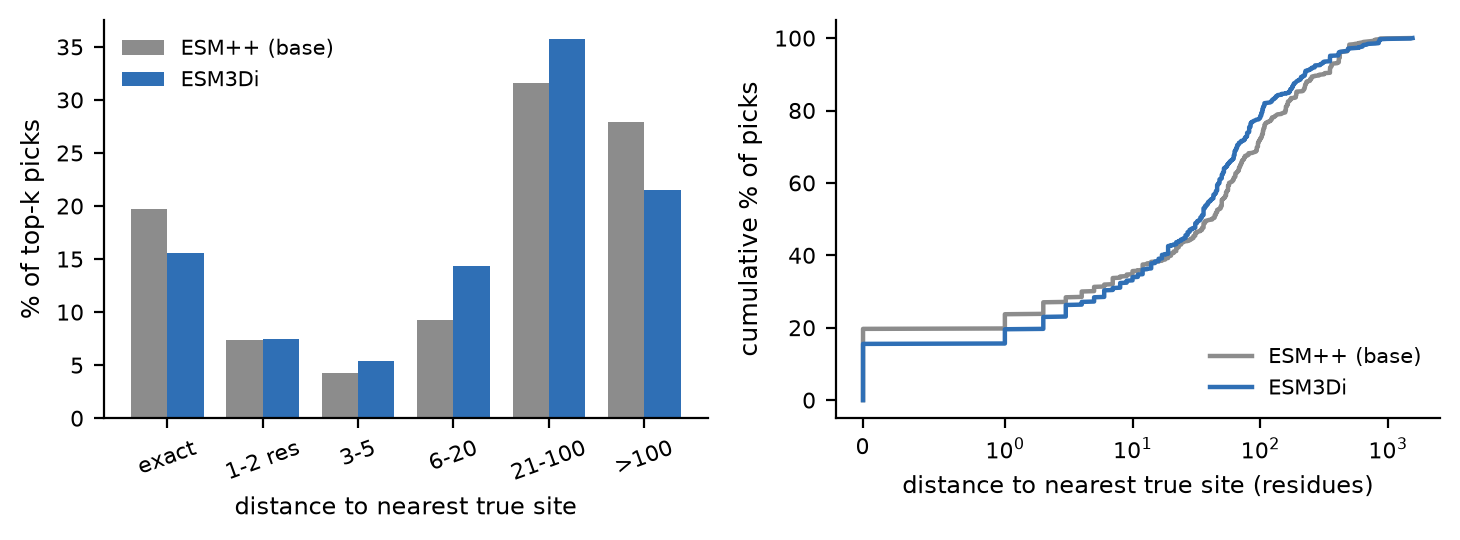

wrote cutsite_pick_distances.png


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(7.4, 2.8), dpi=200)
names = [b[2] for b in BUCKETS]; x = np.arange(len(names)); w = 0.38
for i, arm in enumerate(["base", "esm3di"]):
    frac = [((DIST[arm] >= lo) & (DIST[arm] <= hi)).mean() for lo, hi, _ in BUCKETS]
    ax[0].bar(x + (i-0.5)*w, [100*f for f in frac], w, color=C[arm],
              label=AL[arm])
ax[0].set_xticks(x); ax[0].set_xticklabels(names, fontsize=7.5, rotation=20)
ax[0].set_ylabel("% of top-k picks", fontsize=9)
ax[0].set_xlabel("distance to nearest true site", fontsize=8.5)
ax[0].legend(fontsize=7.5, frameon=False)
ax[0].tick_params(labelsize=8)
for s in ("top","right"): ax[0].spines[s].set_visible(False)

for arm in ("base", "esm3di"):
    d = np.sort(DIST[arm])
    ax[1].plot(np.r_[0, d], np.r_[0, np.arange(1, len(d)+1)/len(d)*100],
               color=C[arm], lw=1.6, label=AL[arm])
ax[1].set_xscale("symlog", linthresh=1)
ax[1].set_xlabel("distance to nearest true site (residues)", fontsize=8.5)
ax[1].set_ylabel("cumulative % of picks", fontsize=9)
ax[1].legend(fontsize=7.5, frameon=False, loc="lower right")
ax[1].tick_params(labelsize=8)
for s in ("top","right"): ax[1].spines[s].set_visible(False)
plt.tight_layout(); plt.savefig("cutsite_pick_distances.png", bbox_inches="tight")
plt.show()
print("wrote cutsite_pick_distances.png")

## 8. Summary figure

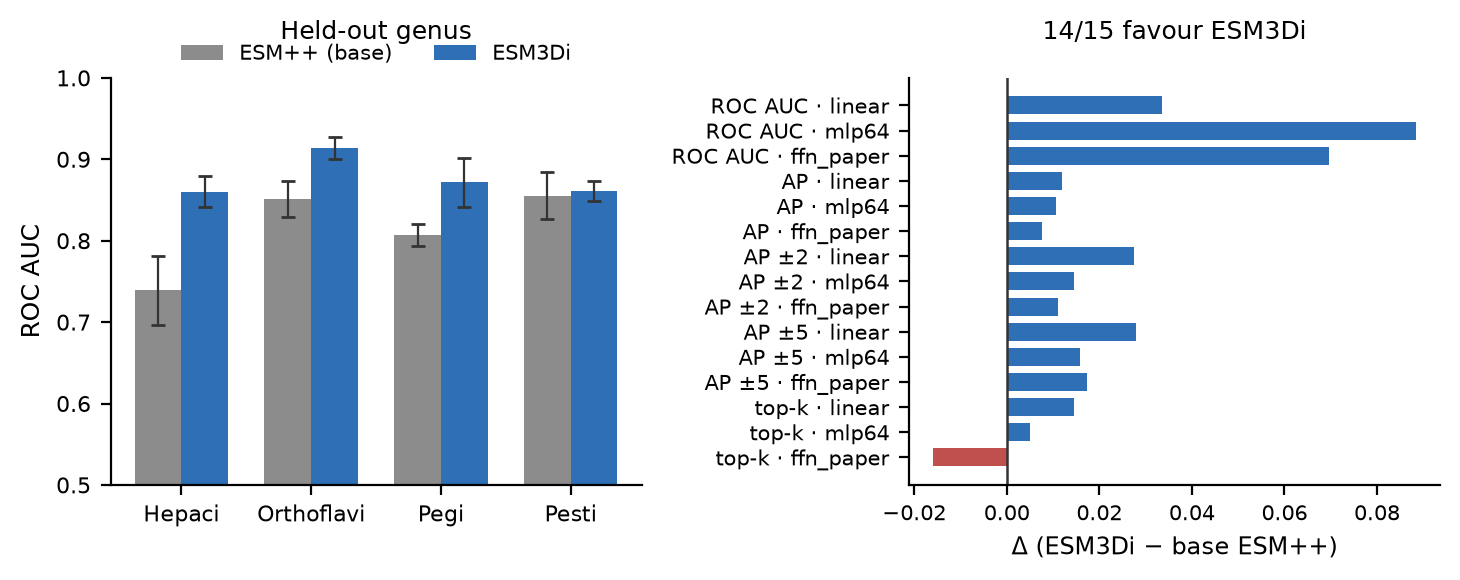

wrote cutsite_basemodel_panel.{png,pdf} and cutsite_basemodel_results.csv


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.0), dpi=200)
gs = sorted(R.group.unique()); x = np.arange(len(gs)); w = 0.36
for i, arm in enumerate(["base","esm3di"]):
    mu = [R[(R.group==g)&(R.arm==arm)].roc_auc.mean() for g in gs]
    sd = [R[(R.group==g)&(R.arm==arm)].roc_auc.std()  for g in gs]
    ax[0].bar(x+(i-0.5)*w, mu, w, yerr=sd, capsize=2.5, color=C[arm],
              label=AL[arm],
              error_kw=dict(lw=0.8, ecolor="#333"))
ax[0].set_xticks(x); ax[0].set_xticklabels([SH[g] for g in gs], fontsize=8)
ax[0].set_ylim(0.5, 1.0); ax[0].set_ylabel("ROC AUC", fontsize=9)
ax[0].set_title("Held-out genus", fontsize=9, pad=14)
ax[0].legend(fontsize=7.5, frameon=False, ncol=2, loc="upper center",
             bbox_to_anchor=(0.5, 1.13))
ax[0].tick_params(labelsize=8)
for s in ("top","right"): ax[0].spines[s].set_visible(False)

labels, vals = [], []
for k in ["roc_auc","ap","ap_t2","ap_t5","topk"]:
    for h in ["linear","mlp64","ffn_paper"]:
        g = R[R["head"]==h].groupby(["group","arm"])[k].mean().unstack("arm")
        vals.append((g["esm3di"]-g["base"]).mean()); labels.append(f"{ML[k]} · {h}")
y = np.arange(len(vals))
ax[1].barh(y, vals, color=["#2f6fb5" if v>0 else "#c0504d" for v in vals], height=0.72)
ax[1].axvline(0, color="#333", lw=0.9)
ax[1].set_yticks(y); ax[1].set_yticklabels(labels, fontsize=6.2); ax[1].invert_yaxis()
ax[1].set_xlabel("Δ (ESM3Di − base ESM++)", fontsize=8.5)
ax[1].set_title(f"{sum(v>0 for v in vals)}/{len(vals)} favour ESM3Di", fontsize=9, pad=14)
ax[1].tick_params(labelsize=7.5)
for s in ("top","right"): ax[1].spines[s].set_visible(False)
plt.tight_layout()
plt.savefig("cutsite_basemodel_panel.png", bbox_inches="tight")
plt.savefig("cutsite_basemodel_panel.pdf", bbox_inches="tight")
R.to_csv("cutsite_basemodel_results.csv", index=False)
plt.show()
print("wrote cutsite_basemodel_panel.{png,pdf} and cutsite_basemodel_results.csv")

## Interpretation

**ESM3Di embeddings beat non-fine-tuned ESM++ embeddings on a task the model was never
trained for.** The effect holds in 11 of 12 head × metric combinations and is largest and
most consistent on ROC AUC (+0.03 to +0.08, winning in 3–4 of 4 held-out genera depending on
head). The linear probe — the cleanest read on representation quality, with no capacity or
hyperparameter confound — favours ESM3Di on all four metrics.

**The gain is in ranking, not at the very top of the ranking.** ROC AUC improves clearly,
but strict single-residue AP is close to even and top-k site recovery is inconsistent.
ESM3Di pushes the bulk of non-cleavage residues below the true sites more effectively,
without improving the hardest false positives. Tolerance-window AP (±2, ±5) sits in
between, improving in 3 of 4 genera on every head.

**The gain is regional, not residue-exact.** Section 7 locates it: ESM3Di's top-k picks land
>100 residues from any true site 21.5% of the time versus 27.9% for base ESM++ (median miss
34 vs 42 residues), while base ESM++ is marginally better at the exact residue (19.7% vs
15.5% exact hits). The fine-tuning improves the sense of where in a polyprotein cleavage
occurs, not which bond is cut — plausible given that 3Di encodes local structural
neighbourhood, which carries domain-boundary information rather than scissile-bond chemistry.

**Absolute performance remains modest.** Top-k recovery is about 0.25, so roughly a quarter
of annotated sites are found among the top *k* peaks. This supports a representation-quality
claim; it does not support presenting the classifier as a competitive cleavage predictor.

**Caveats.**
- Four genera of one viral order, 95 annotated sequences, 940 positive labels. Group-level
  *n* is 4, so per-metric differences rest on four paired observations.
- *Pestivirus* is the one genus where the arms tie or ESM3Di trails on most metrics.
- The adapter used here is the published PEFT checkpoint, not the `.pt` file referenced by
  the original notebook, which is absent from this machine.
- Labels come from ICTV annotation transferred by homology, not from experiment.

If a usable cutter is ever the goal, the natural design follows from Section 7: ESM3Di for
region-finding combined with a motif model for exact placement, which is in effect what
3CLP does with its P1=Q gate.
